## Prepare masked injection calibration cases

This cell constructs the common injection data used by the regularised and
non-regularised tests.

For each injected circle geometry, the two ring windows are obtained from the
CMB mask and the phase-dependent fraction of jointly masked samples is used to
retain only phases satisfying

$$
f_{\mathrm{lost}}(\beta)\leq 0.5.
$$

The mask windows are transformed to Fourier space and used to construct the
three coupling eigenvalue arrays

$$
\mu_{ij},\qquad
\mu_{ii},\qquad
\mu_{jj},
$$

which are required later for the regularised inverse.

Each injection is evaluated in the appropriate search branch,

$$
25^\circ\leq\alpha\leq48^\circ
\quad\rightarrow\quad
\text{filtered},
$$

and

$$
42^\circ\leq\alpha\leq90^\circ
\quad\rightarrow\quad
\text{unfiltered}.
$$

The full-map reference statistic is calculated from the unmasked Fourier
products,

$$
C_{ij}=T_iT_j,
\qquad
C_{ii}=|T_i|^2,
\qquad
C_{jj}=|T_j|^2,
$$

using

$$
S(\beta)
=
\frac{
2\displaystyle\sum_{m=m_{\min}} m\,
\mathrm{Re}\!\left[C_{ij}(m)e^{-im\beta}\right]
}{
\displaystyle\sum_{m=m_{\min}} m
\left[
C_{ii}(m)+C_{jj}(m)
\right]
}.
$$

For each calibration case, the cell stores the masked mode products,
the corresponding full-map $S(\beta)$ curve, the search branch, opening angle,
and $f_{\mathrm{lost}}$ information for the later regularisation tests.

In [1]:
from pathlib import Path

import healpy as hp
import numpy as np
import pandas as pd
from IPython.display import display


# ==================================================
# Paths and settings
# ==================================================

ROOT = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

INJECTION_DIR = (
    ROOT
    / "perfect_injection_nside128_lmax300_batch"
)

INJECTION_CATALOGUE_FILE = (
    INJECTION_DIR
    / "injection_catalogue.csv"
)

MASK_FILE = (
    ROOT
    / "src"
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

FILTER_FILE = (
    ROOT
    / "SW_Doppler_ISW_filter_lmax300.dat"
)

NSIDE_MAP = 128
NSIDE_SEARCH = 128
NSIDE_MASK = 128

NPHI = 128
LMAX = 300
M_MIN = 2
MASK_THRESHOLD = 0.5

F_LOST_EDGES = np.array(
    [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
)


# ==================================================
# Read updated injection catalogue
# ==================================================

injection_catalogue = pd.read_csv(
    INJECTION_CATALOGUE_FILE
)

required_columns = {
    "injection_id",
    "alpha_deg",
    "pixel_i",
    "pixel_j",
    "f_lost",
    "injected_file",
}

missing_columns = (
    required_columns
    - set(injection_catalogue.columns)
)

if missing_columns:
    raise RuntimeError(
        f"Missing catalogue columns: "
        f"{sorted(missing_columns)}"
    )

if injection_catalogue[
    "injection_id"
].duplicated().any():
    raise RuntimeError(
        "Duplicate injection_id values in injection_catalogue.csv"
    )


# ==================================================
# Load mask
# ==================================================

mask = hp.read_map(
    MASK_FILE,
    field=0,
    dtype=np.float64,
    nest=False,
)

if hp.get_nside(mask) != NSIDE_MASK:
    raise RuntimeError(
        f"Expected mask Nside={NSIDE_MASK}; "
        f"found {hp.get_nside(mask)}"
    )


# ==================================================
# Load filtered-branch harmonic filter
# ==================================================

filter_table = np.atleast_2d(
    np.loadtxt(
        FILTER_FILE,
        comments="#",
    )
)

filter_values = np.zeros(
    LMAX + 1
)

ell = filter_table[:, 0].astype(int)

use = (
    (ell >= 0)
    & (ell <= LMAX)
)

filter_values[ell[use]] = (
    filter_table[use, 1]
)


# ==================================================
# Circle geometry helpers
# ==================================================

window_cache = {}


def circle_angles(
    centre_pixel,
    alpha_deg,
):
    theta_c, phi_c = hp.pix2ang(
        NSIDE_SEARCH,
        int(centre_pixel),
        nest=False,
    )

    alpha = np.deg2rad(alpha_deg)

    phase = (
        2.0
        * np.pi
        * np.arange(1, NPHI + 1)
        / NPHI
    )

    x0 = np.sin(alpha) * np.cos(phase)
    y0 = np.sin(alpha) * np.sin(phase)
    z0 = np.full(NPHI, np.cos(alpha))

    ct = np.cos(theta_c)
    st = np.sin(theta_c)
    cp = np.cos(phi_c)
    sp = np.sin(phi_c)

    x = (
        ct * cp * x0
        - sp * y0
        + st * cp * z0
    )

    y = (
        ct * sp * x0
        + cp * y0
        + st * sp * z0
    )

    z = (
        -st * x0
        + ct * z0
    )

    theta = np.arccos(
        np.clip(z, -1.0, 1.0)
    )

    phi = np.mod(
        np.arctan2(y, x),
        2.0 * np.pi,
    )

    return theta, phi


def get_window(
    centre_pixel,
    alpha_deg,
):
    key = (
        int(centre_pixel),
        float(alpha_deg),
    )

    if key not in window_cache:
        theta, phi = circle_angles(
            centre_pixel,
            alpha_deg,
        )

        map_pixels = hp.ang2pix(
            NSIDE_MAP,
            theta,
            phi,
            nest=False,
        )

        mask_pixels = hp.ang2pix(
            NSIDE_MASK,
            theta,
            phi,
            nest=False,
        )

        window = (
            mask[mask_pixels]
            >= MASK_THRESHOLD
        ).astype(float)

        window_cache[key] = (
            map_pixels,
            window,
        )

    return window_cache[key]


def losses_by_beta(
    w_i,
    w_j,
):
    n_joint = np.fft.ifft(
        np.fft.fft(w_i)
        * np.fft.fft(w_j)
    ).real

    return (
        1.0
        - np.clip(
            np.rint(n_joint),
            0,
            NPHI,
        )
        / NPHI
    )


def f_lost_bin_index(
    f_lost,
):
    index = int(
        np.searchsorted(
            F_LOST_EDGES,
            f_lost,
            side="right",
        )
        - 1
    )

    return min(
        max(index, 0),
        len(F_LOST_EDGES) - 2,
    )


def f_lost_bin_label(
    index,
):
    return (
        f"{F_LOST_EDGES[index]:.1f}–"
        f"{F_LOST_EDGES[index + 1]:.1f}"
    )


def branches_for_alpha(
    alpha_deg,
):
    branches = []

    if 25.0 <= alpha_deg <= 48.0:
        branches.append("filtered")

    if 42.0 <= alpha_deg <= 90.0:
        branches.append("unfiltered")

    return branches


# ==================================================
# Build geometry_by_injection
# ==================================================

geometry_by_injection = {}

for row in injection_catalogue.itertuples(
    index=False
):
    injection_id = int(row.injection_id)
    alpha_deg = float(row.alpha_deg)
    pixel_i = int(row.pixel_i)
    pixel_j = int(row.pixel_j)

    pixels_i, w_i = get_window(
        pixel_i,
        alpha_deg,
    )

    pixels_j, w_j = get_window(
        pixel_j,
        alpha_deg,
    )

    beta_losses = losses_by_beta(
        w_i,
        w_j,
    )

    W_i = np.fft.fft(w_i) / NPHI
    W_j = np.fft.fft(w_j) / NPHI

    geometry_by_injection[injection_id] = {
        "injection_id": injection_id,
        "alpha_deg": alpha_deg,
        "pixel_i": pixel_i,
        "pixel_j": pixel_j,
        "pixels_i": pixels_i,
        "pixels_j": pixels_j,
        "w_i": w_i,
        "w_j": w_j,
        "f_lost": float(row.f_lost),
        "eligible_beta": beta_losses <= 0.5,
        "mu_ij": np.fft.fft(
            W_i * W_j
        ),
        "mu_ii": np.fft.fft(
            W_i * np.conj(W_i)
        ),
        "mu_jj": np.fft.fft(
            W_j * np.conj(W_j)
        ),
    }


# ==================================================
# S(beta) and filtered branch
# ==================================================

M = np.arange(
    NPHI // 2 + 1,
    dtype=float,
)


def calculate_S(
    C_ij,
    C_ii,
    C_jj,
):
    denominator = np.sum(
        M[M_MIN:]
        * (
            np.real(
                C_ii[
                    M_MIN:NPHI // 2 + 1
                ]
            )
            + np.real(
                C_jj[
                    M_MIN:NPHI // 2 + 1
                ]
            )
        )
    )

    if (
        not np.isfinite(denominator)
        or denominator <= 0.0
    ):
        return None

    modes = np.zeros(
        NPHI // 2 + 1,
        dtype=np.complex128,
    )

    modes[M_MIN:] = (
        M[M_MIN:]
        * C_ij[
            M_MIN:NPHI // 2 + 1
        ]
    )

    return (
        np.real(
            np.fft.irfft(
                modes,
                n=NPHI,
            )
            * NPHI
        )
        / denominator
    )


def apply_filter(
    sky_map,
):
    alm = hp.map2alm(
        sky_map,
        lmax=LMAX,
        iter=0,
        pol=False,
        use_weights=False,
    )

    return hp.alm2map(
        hp.almxfl(
            alm,
            filter_values,
            inplace=False,
        ),
        nside=NSIDE_MAP,
        lmax=LMAX,
        pol=False,
    )


# ==================================================
# Read injection maps and construct calibration cases
# ==================================================

cases = []

for map_number, row in enumerate(
    injection_catalogue.itertuples(
        index=False
    ),
    start=1,
):
    injection_id = int(row.injection_id)
    map_file = Path(row.injected_file)

    if not map_file.exists():
        raise FileNotFoundError(map_file)

    full_map = hp.read_map(
        map_file,
        field=0,
        dtype=np.float64,
        nest=False,
    )

    if hp.get_nside(full_map) != NSIDE_MAP:
        raise RuntimeError(
            f"Injection {injection_id}: "
            f"expected Nside={NSIDE_MAP}; "
            f"found Nside={hp.get_nside(full_map)}"
        )

    geometry = geometry_by_injection[
        injection_id
    ]

    alpha_deg = geometry["alpha_deg"]
    branches = branches_for_alpha(alpha_deg)

    if not branches:
        raise RuntimeError(
            f"Injection {injection_id}: "
            f"alpha={alpha_deg} is outside both search branches"
        )

    branch_maps = {
        "unfiltered": full_map,
    }

    if "filtered" in branches:
        branch_maps["filtered"] = apply_filter(
            full_map
        )

    f_lost = geometry["f_lost"]
    f_bin = f_lost_bin_index(f_lost)

    for branch in branches:
        branch_map = branch_maps[branch]

        ring_i = branch_map[
            geometry["pixels_i"]
        ]

        ring_j = branch_map[
            geometry["pixels_j"]
        ]

        T_i = np.fft.fft(ring_i)
        T_j = np.fft.fft(ring_j)

        T_hat_i = np.fft.fft(
            geometry["w_i"] * ring_i
        )

        T_hat_j = np.fft.fft(
            geometry["w_j"] * ring_j
        )

        full_S = calculate_S(
            T_i * T_j,
            np.abs(T_i) ** 2,
            np.abs(T_j) ** 2,
        )

        if full_S is None:
            raise RuntimeError(
                f"Injection {injection_id}: invalid full S(beta)"
            )

        full_S[
            ~geometry["eligible_beta"]
        ] = np.nan

        cases.append(
            {
                "injection_id": injection_id,
                "injected_file": str(map_file),
                "branch": branch,
                "alpha_deg": alpha_deg,
                "f_lost": f_lost,
                "f_lost_bin": f_bin,
                "f_lost_bin_label": f_lost_bin_label(
                    f_bin
                ),
                "C_hat_ij": T_hat_i * T_hat_j,
                "C_hat_ii": np.abs(T_hat_i) ** 2,
                "C_hat_jj": np.abs(T_hat_j) ** 2,
                "full_S": full_S,
            }
        )

    print(
        f"Prepared injection "
        f"{map_number:03d}/"
        f"{len(injection_catalogue):03d}"
    )


# ==================================================
# Check prepared objects
# ==================================================

case_coverage = (
    pd.DataFrame(
        [
            {
                "branch": case["branch"],
                "f_lost_bin": case[
                    "f_lost_bin_label"
                ],
            }
            for case in cases
        ]
    )
    .groupby(
        [
            "branch",
            "f_lost_bin",
        ],
        observed=True,
    )
    .size()
    .rename("cases")
    .reset_index()
)

print(
    "\nInjection maps:",
    len(injection_catalogue),
)

print(
    "Geometries:",
    len(geometry_by_injection),
)

print(
    "Prepared cases:",
    len(cases),
)

display(
    case_coverage
)


Prepared injection 001/147
Prepared injection 002/147
Prepared injection 003/147
Prepared injection 004/147
Prepared injection 005/147
Prepared injection 006/147
Prepared injection 007/147
Prepared injection 008/147
Prepared injection 009/147
Prepared injection 010/147
Prepared injection 011/147
Prepared injection 012/147
Prepared injection 013/147
Prepared injection 014/147
Prepared injection 015/147
Prepared injection 016/147
Prepared injection 017/147
Prepared injection 018/147
Prepared injection 019/147
Prepared injection 020/147
Prepared injection 021/147
Prepared injection 022/147
Prepared injection 023/147
Prepared injection 024/147
Prepared injection 025/147
Prepared injection 026/147
Prepared injection 027/147
Prepared injection 028/147
Prepared injection 029/147
Prepared injection 030/147
Prepared injection 031/147
Prepared injection 032/147
Prepared injection 033/147
Prepared injection 034/147
Prepared injection 035/147
Prepared injection 036/147
Prepared injection 037/147
P

,branch,f_lost_bin,cases
0,filtered,0.0–0.1,10
1,filtered,0.1–0.2,10
2,filtered,0.2–0.3,10
3,filtered,0.3–0.4,10
4,filtered,0.4–0.5,26
5,unfiltered,0.0–0.1,10
6,unfiltered,0.1–0.2,16
7,unfiltered,0.2–0.3,16
8,unfiltered,0.3–0.4,18
9,unfiltered,0.4–0.5,33


## Calibrate the $f_{\mathrm{lost}}$-dependent Tikhonov regularisation

This cell calibrates and tests the regularisation strength using the simulated
matched-circle injections.

For each reconstructed quantity

$$
a\in\{ij,ii,jj\},
$$

define the coupling loss of Fourier mode $q$ as

$$
L_{a,q}
=
1-
\frac{|\mu_{a,q}|^2}{\mu_{a,\max}^2}.
$$

The mode-dependent Tikhonov regularisation is then

$$
\lambda_{a,q}^2
=
A\,\mu_{a,\max}^2
\frac{f_{\mathrm{lost},a}}
{1-f_{\mathrm{lost},a}}
L_{a,q},
$$

so that poorly coupled modes and more heavily masked circles receive stronger
regularisation.

The reconstructed mode product is

$$
C^{\mathrm{rec}}_{a,q}
=
\frac{
\mu_{a,q}^{*}
}{
|\mu_{a,q}|^2+\lambda_{a,q}^2
}
\widehat C_{a,q}.
$$

Only the branch used by the actual search is retained,

$$
\alpha<45^\circ
\quad\rightarrow\quad
\text{filtered},
$$

and

$$
\alpha\geq45^\circ
\quad\rightarrow\quad
\text{unfiltered}.
$$

The injection set is divided at the injection-map level into training and
held-out test samples, while maintaining coverage across the observed
branch, cross/auto, and $f_{\mathrm{lost}}$ bins.

A single global amplitude $A$ is selected from the training injections by
minimising

$$
\mathrm{MSE}(A)
=
\frac{1}{N_{\mathrm{train}}}
\sum_k
\left[
S_{\max,k}^{\mathrm{rec}}(A)
-
S_{\max,k}^{\mathrm{full}}
\right]^2.
$$

The selected value is then applied without further tuning to the held-out
injections. For each test case, the cell records the recovered and full-map
$S_{\max}$ values, their difference

$$
\Delta S_{\max}
=
S_{\max}^{\mathrm{rec}}
-
S_{\max}^{\mathrm{full}},
$$

and the corresponding phase-recovery error for use in the subsequent
regularised-performance histogram.

Filtered cases: 55
Unfiltered cases: 92
Cross/auto train/test coverage:


,branch,quantity,f_lost_bin,role,maps
0,filtered,auto,0.0–0.1,test,10
1,filtered,auto,0.0–0.1,train,10
2,filtered,auto,0.1–0.2,test,12
3,filtered,auto,0.1–0.2,train,12
4,filtered,auto,0.2–0.3,test,10
5,filtered,auto,0.2–0.3,train,11
6,filtered,auto,0.3–0.4,test,6
7,filtered,auto,0.3–0.4,train,6
8,filtered,auto,0.4–0.5,test,6
9,filtered,auto,0.4–0.5,train,3


Selected A: 0.08912509381337459
Training Smax MSE: 0.0024913278186400505


,A,training_Smax_MSE
0,0.000000,0.002813
1,0.010000,0.002741
2,0.010593,0.002737
3,0.011220,0.002733
4,0.011885,0.002729
...,...,...
117,7.943282,0.119043
118,8.413951,0.122879
119,8.912509,0.126763
120,9.440609,0.130678


Held-out individual results:


,injection_id,branch,alpha_deg,A,f_lost_ij,f_lost_bin_ij,f_lost_ii,f_lost_bin_ii,f_lost_jj,f_lost_bin_jj,Full Smax,Recovered Smax,Smax error,Absolute Smax error,Full beta bin,Recovered beta bin,Beta error in bins,S(beta) RMSE,injected_file
0,0,filtered,25.0,0.089125,0.025391,0.0–0.1,0.015625,0.0–0.1,0.007812,0.0–0.1,0.446103,0.460135,0.014032,0.014032,126,126,0,0.012219,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
1,2,filtered,25.0,0.089125,0.126953,0.1–0.2,0.062500,0.0–0.1,0.054688,0.0–0.1,0.479178,0.495979,0.016801,0.016801,126,126,0,0.042145,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
2,3,filtered,25.0,0.089125,0.173828,0.1–0.2,0.125000,0.1–0.2,0.046875,0.0–0.1,0.504091,0.543746,0.039654,0.039654,126,126,0,0.043634,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
3,5,filtered,25.0,0.089125,0.273438,0.2–0.3,0.179688,0.1–0.2,0.093750,0.0–0.1,0.410559,0.401553,-0.009007,0.009007,126,126,0,0.060720,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
4,6,filtered,25.0,0.089125,0.324219,0.3–0.4,0.156250,0.1–0.2,0.179688,0.1–0.2,0.436044,0.532628,0.096584,0.096584,126,126,0,0.062185,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,140,unfiltered,89.0,0.089125,0.472656,0.4–0.5,0.406250,0.4–0.5,0.429688,0.4–0.5,0.833361,0.839772,0.006411,0.006411,126,126,0,0.099747,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
70,142,unfiltered,90.0,0.089125,0.412109,0.4–0.5,0.406250,0.4–0.5,0.406250,0.4–0.5,0.991331,1.005900,0.014569,0.014569,126,126,0,0.155353,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
71,143,unfiltered,88.0,0.089125,0.488281,0.4–0.5,0.398438,0.3–0.4,0.390625,0.3–0.4,0.882556,0.927724,0.045168,0.045168,126,126,0,0.040638,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
72,144,unfiltered,90.0,0.089125,0.414062,0.4–0.5,0.382812,0.3–0.4,0.382812,0.3–0.4,0.998919,1.001670,0.002751,0.002751,126,126,0,0.076665,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...


Held-out summary:


,branch,test_maps,mean_full_Smax,mean_recovered_Smax,mean_signed_Smax_error,mean_absolute_Smax_error,maximum_absolute_Smax_error,mean_beta_error_bins,mean_Sbeta_RMSE
0,filtered,27,0.343820,0.355342,0.011522,0.042653,0.115819,1.925926,0.057404
1,unfiltered,47,0.880114,0.877401,-0.002713,0.039821,0.148791,0.000000,0.063699


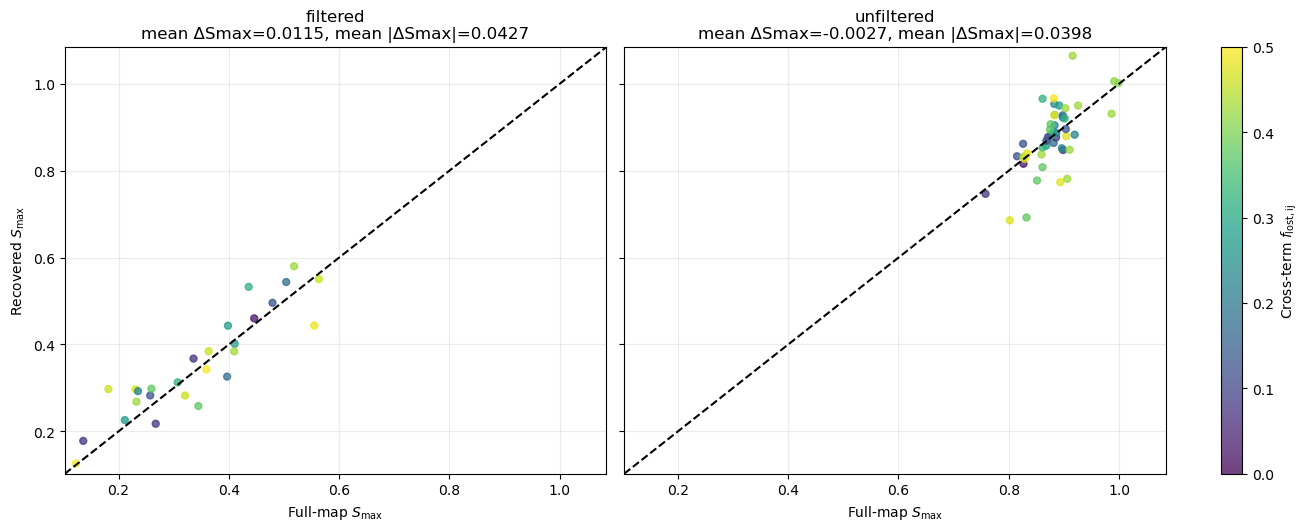

Saved: /hydrarepo/xluo/circles-in-the-sky/perfect_injection_nside128_lmax300_batch/unbinned_f_lost_tikhonov_test_results.csv
Saved: /hydrarepo/xluo/circles-in-the-sky/perfect_injection_nside128_lmax300_batch/unbinned_f_lost_tikhonov_test_summary.csv
Saved: /hydrarepo/xluo/circles-in-the-sky/perfect_injection_nside128_lmax300_batch/unbinned_f_lost_tikhonov_recovery.png


In [2]:
import matplotlib.pyplot as plt

# ==================================================
# f_lost- and coupling-dependent Tikhonov regularisation
#
# For each a = ij, ii, jj:
#
#   L_a,q
#       = 1 - |mu_a,q|^2 / mu_a,max^2
#
#   w_a,q
#       = 1 - L_a,q
#
#   lambda_a,q^2
#       = A * mu_a,max^2
#         * f_lost,a / (1 - f_lost,a)
#         * w_a,q
#
#   C_rec_a,q
#       = mu_a,q^*
#         / (|mu_a,q|^2 + lambda_a,q^2)
#         * C_hat_a,q
#
# A is selected globally from the training injections.
# ==================================================

RNG = np.random.default_rng(20260831)

QUANTITIES = ("ij", "ii", "jj")

# Wide, dense search grid for A.
A_GRID = np.concatenate(
    (
        [0.0],
        np.logspace(
            -2.0,
            1.0,
            121,
        ),
    )
)

# ==================================================
# Keep only the branch used by the actual search
# ==================================================

cases = [
    case
    for case in cases
    if (
        (
            case["alpha_deg"] < 45.0
            and case["branch"] == "filtered"
        )
        or
        (
            case["alpha_deg"] >= 45.0
            and case["branch"] == "unfiltered"
        )
    )
]
print(
    "Filtered cases:",
    sum(
        case["branch"] == "filtered"
        for case in cases
    ),
)

print(
    "Unfiltered cases:",
    sum(
        case["branch"] == "unfiltered"
        for case in cases
    ),
)

assert all(
    (
        case["branch"] == "filtered"
        and case["alpha_deg"] < 45.0
    )
    or
    (
        case["branch"] == "unfiltered"
        and case["alpha_deg"] >= 45.0
    )
    for case in cases
)

# ==================================================
# Add quantity-specific f_lost values and diagnostic bins
# ==================================================

for case in cases:
    geometry = geometry_by_injection[
        case["injection_id"]
    ]

    # The catalogue f_lost is the cross-term loss.
    case["f_lost_ij"] = float(
        case["f_lost"]
    )

    # Auto losses come from the two individual windows.
    case["f_lost_ii"] = float(
        1.0 - np.mean(geometry["w_i"])
    )
    case["f_lost_jj"] = float(
        1.0 - np.mean(geometry["w_j"])
    )

    for quantity in QUANTITIES:
        loss = case[f"f_lost_{quantity}"]

        if not 0.0 <= loss < 0.5:
            raise RuntimeError(
                f"Injection {case['injection_id']}, "
                f"{quantity}: f_lost={loss:.6f} "
                "is outside [0, 0.5)"
            )

        f_bin = f_lost_bin_index(loss)

        case[f"f_lost_bin_{quantity}"] = f_bin
        case[
            f"f_lost_bin_label_{quantity}"
        ] = f_lost_bin_label(f_bin)


# ==================================================
# Split complete injection maps into train/test sets
# ==================================================

injection_ids = np.array(
    sorted(
        {
            int(case["injection_id"])
            for case in cases
        }
    )
)

number_training_maps = len(injection_ids) // 2


# Require train/test coverage in every observed
# branch/cross-or-auto/f_lost bin.
quantity_groups = {}

for branch in ("filtered", "unfiltered"):
    for f_bin in range(5):
        cross_identifiers = {
            int(case["injection_id"])
            for case in cases
            if (
                case["branch"] == branch
                and case["f_lost_bin_ij"] == f_bin
            )
        }

        # ii and jj share one auto catalogue.
        auto_identifiers = {
            int(case["injection_id"])
            for case in cases
            if (
                case["branch"] == branch
                and (
                    case["f_lost_bin_ii"] == f_bin
                    or case["f_lost_bin_jj"] == f_bin
                )
            )
        }

        for table_type, identifiers in (
            ("ij", cross_identifiers),
            ("auto", auto_identifiers),
        ):
            if not identifiers:
                continue

            if len(identifiers) < 2:
                raise RuntimeError(
                    f"Only one injection for {branch}, "
                    f"{table_type}, f_lost="
                    f"{f_lost_bin_label(f_bin)}"
                )

            quantity_groups[
                (branch, table_type, f_bin)
            ] = identifiers


# Find a reproducible injection-level split with
# coverage in both halves.
best_training_ids = None
best_balance_score = np.inf

for _ in range(10000):
    shuffled = injection_ids.copy()
    RNG.shuffle(shuffled)

    candidate_training_ids = set(
        shuffled[:number_training_maps]
    )

    valid_split = True
    balance_score = 0.0

    for identifiers in quantity_groups.values():
        n_train = len(
            identifiers & candidate_training_ids
        )
        n_test = len(identifiers) - n_train

        if n_train == 0 or n_test == 0:
            valid_split = False
            break

        balance_score += abs(
            n_train - len(identifiers) / 2.0
        )

    if (
        valid_split
        and balance_score < best_balance_score
    ):
        best_training_ids = candidate_training_ids
        best_balance_score = balance_score

        if balance_score == 0.0:
            break


if best_training_ids is None:
    raise RuntimeError(
        "Could not find an injection-level train/test "
        "split with coverage in every observed "
        "cross/auto bin"
    )


for case in cases:
    case["role"] = (
        "train"
        if case["injection_id"] in best_training_ids
        else "test"
    )


train_cases = [
    case
    for case in cases
    if case["role"] == "train"
]

test_cases = [
    case
    for case in cases
    if case["role"] == "test"
]


# ==================================================
# Display train/test coverage
# ==================================================

coverage_rows = []

for case in cases:
    coverage_rows.append(
        {
            "injection_id": case["injection_id"],
            "branch": case["branch"],
            "quantity": "ij",
            "f_lost_bin": (
                case["f_lost_bin_label_ij"]
            ),
            "role": case["role"],
        }
    )

    for auto_quantity in ("ii", "jj"):
        coverage_rows.append(
            {
                "injection_id": case["injection_id"],
                "branch": case["branch"],
                "quantity": "auto",
                "f_lost_bin": case[
                    f"f_lost_bin_label_{auto_quantity}"
                ],
                "role": case["role"],
            }
        )


quantity_coverage = (
    pd.DataFrame(coverage_rows)
    .drop_duplicates(
        subset=[
            "injection_id",
            "branch",
            "quantity",
            "f_lost_bin",
            "role",
        ]
    )
    .groupby(
        [
            "branch",
            "quantity",
            "f_lost_bin",
            "role",
        ],
        observed=True,
    )
    .agg(maps=("injection_id", "nunique"))
    .reset_index()
)

print("Cross/auto train/test coverage:")
display(quantity_coverage)

# ==================================================
# Direct f_lost-dependent Tikhonov inverse
# ==================================================
def inverse_f_lost(
    C_hat,
    mu,
    f_lost,
    A,
):
    C_hat = np.asarray(C_hat)
    mu = np.asarray(mu)

    maximum_mu = float(
        np.max(np.abs(mu))
    )

    if maximum_mu == 0.0:
        raise RuntimeError(
            "All coupling eigenvalues are zero"
        )

    if not 0.0 <= f_lost < 1.0:
        raise ValueError(
            "f_lost must satisfy 0 <= f_lost < 1"
        )

    coupling_loss = (
        1.0
        - np.abs(mu) ** 2
        / maximum_mu**2
    )

    spectral_weight = (
        coupling_loss
    )

    lambda_squared = (
        A
        * maximum_mu**2
        * f_lost
        / (1.0 - f_lost)
        * spectral_weight
    )

    denominator = (
        np.abs(mu) ** 2
        + lambda_squared
    )

    inverse_filter = np.zeros(
        mu.shape,
        dtype=np.complex128,
    )

    valid = denominator > 0.0

    inverse_filter[valid] = (
        np.conj(mu[valid])
        / denominator[valid]
    )

    return np.fft.ifft(
        np.fft.fft(C_hat)
        * inverse_filter
    )

# ==================================================
# Recover S(beta) for one case
# ==================================================
def recover_case(
    case,
    A,
):

    geometry = geometry_by_injection[
        case["injection_id"]
    ]

    recovered_ij = inverse_f_lost(
        case["C_hat_ij"],
        geometry["mu_ij"],
        case["f_lost_ij"],
        A,
    )

    recovered_ii = inverse_f_lost(
        case["C_hat_ii"],
        geometry["mu_ii"],
        case["f_lost_ii"],
        A,
    )

    recovered_jj = inverse_f_lost(
        case["C_hat_jj"],
        geometry["mu_jj"],
        case["f_lost_jj"],
        A,
    )

    recovered_S = calculate_S(
        recovered_ij,
        recovered_ii,
        recovered_jj,
    )

    if recovered_S is None:
        raise RuntimeError(
            "Invalid recovered S(beta)"
        )

    recovered_S[
        ~geometry["eligible_beta"]
    ] = np.nan

    return recovered_S

# ==================================================
# Select the best global A from training injections
# ==================================================

A_rows = []

for A in A_GRID:

    squared_errors = []

    for case in train_cases:

        recovered_S = recover_case(
            case,
            A,
        )

        recovered_smax = float(
            np.nanmax(
                recovered_S
            )
        )

        full_smax = float(
            np.nanmax(
                case["full_S"]
            )
        )

        squared_errors.append(
            (
                recovered_smax
                - full_smax
            ) ** 2
        )

    mse = float(
        np.mean(
            squared_errors
        )
    )

    A_rows.append(
        {
            "A": float(A),
            "training_Smax_MSE": mse,
        }
    )


A_scan = pd.DataFrame(
    A_rows
)

best_row = A_scan.loc[
    A_scan[
        "training_Smax_MSE"
    ].idxmin()
]

SELECTED_A = float(
    best_row["A"]
)

print(
    "Selected A:",
    SELECTED_A,
)

print(
    "Training Smax MSE:",
    best_row[
        "training_Smax_MSE"
    ],
)

display(
    A_scan
)


# ==================================================
# Apply to held-out injection maps
# ==================================================

result_rows = []

for case in test_cases:

    branch = case["branch"]

    recovered_S = recover_case(
        case,
        SELECTED_A,
    )
    
    full_S = case["full_S"]

    valid = (
        np.isfinite(recovered_S)
        & np.isfinite(full_S)
    )

    if not np.any(valid):
        raise RuntimeError(
            f"Injection {case['injection_id']}: "
            "no valid beta"
        )

    full_for_max = np.where(
        valid,
        full_S,
        -np.inf,
    )

    recovered_for_max = np.where(
        valid,
        recovered_S,
        -np.inf,
    )

    full_beta = int(
        np.argmax(full_for_max)
    )

    recovered_beta = int(
        np.argmax(recovered_for_max)
    )

    full_smax = float(
        full_for_max[full_beta]
    )

    recovered_smax = float(
        recovered_for_max[recovered_beta]
    )

    beta_difference = abs(
        recovered_beta - full_beta
    )

    result_rows.append(
        {
            "injection_id": case["injection_id"],
            "branch": branch,
            "alpha_deg": case["alpha_deg"],
            "A": SELECTED_A,

            "f_lost_ij": case["f_lost_ij"],
            "f_lost_bin_ij": (
                case["f_lost_bin_label_ij"]
            ),
            "f_lost_ii": case["f_lost_ii"],
            "f_lost_bin_ii": (
                case["f_lost_bin_label_ii"]
            ),
            "f_lost_jj": case["f_lost_jj"],
            "f_lost_bin_jj": (
                case["f_lost_bin_label_jj"]
            ),
            "Full Smax": full_smax,
            "Recovered Smax": recovered_smax,

            "Smax error": (
                recovered_smax
                - full_smax
            ),

            "Absolute Smax error": abs(
                recovered_smax
                - full_smax
            ),

            "Full beta bin": full_beta,
            "Recovered beta bin": recovered_beta,

            "Beta error in bins": min(
                beta_difference,
                NPHI - beta_difference,
            ),

            "S(beta) RMSE": float(
                np.sqrt(
                    np.mean(
                        (
                            recovered_S[valid]
                            - full_S[valid]
                        ) ** 2
                    )
                )
            ),

            "injected_file": case["injected_file"],
        }
    )


quantity_test_results = pd.DataFrame(
    result_rows
)


# ==================================================
# Held-out summary
# ==================================================

quantity_test_summary = (
    quantity_test_results
    .groupby(
        "branch",
        observed=True,
    )
    .agg(
        test_maps=(
            "injection_id",
            "nunique",
        ),

        mean_full_Smax=(
            "Full Smax",
            "mean",
        ),

        mean_recovered_Smax=(
            "Recovered Smax",
            "mean",
        ),

        mean_signed_Smax_error=(
            "Smax error",
            "mean",
        ),

        mean_absolute_Smax_error=(
            "Absolute Smax error",
            "mean",
        ),

        maximum_absolute_Smax_error=(
            "Absolute Smax error",
            "max",
        ),

        mean_beta_error_bins=(
            "Beta error in bins",
            "mean",
        ),

        mean_Sbeta_RMSE=(
            "S(beta) RMSE",
            "mean",
        ),
    )
    .reset_index()
)


print(
    "Held-out individual results:"
)
display(
    quantity_test_results
)

print(
    "Held-out summary:"
)
display(
    quantity_test_summary
)


# ==================================================
# Plot held-out recovery
# Colour uses cross-term f_lost
# ==================================================

lower = min(
    quantity_test_results[
        "Full Smax"
    ].min(),
    quantity_test_results[
        "Recovered Smax"
    ].min(),
) - 0.02

upper = max(
    quantity_test_results[
        "Full Smax"
    ].max(),
    quantity_test_results[
        "Recovered Smax"
    ].max(),
) + 0.02


fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.2),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)


for axis, branch in zip(
    axes,
    (
        "filtered",
        "unfiltered",
    ),
):

    rows = quantity_test_results[
        quantity_test_results[
            "branch"
        ] == branch
    ]

    points = axis.scatter(
        rows["Full Smax"],
        rows["Recovered Smax"],
        c=rows["f_lost_ij"],
        vmin=0.0,
        vmax=0.5,
        cmap="viridis",
        s=25,
        alpha=0.75,
    )

    axis.plot(
        [lower, upper],
        [lower, upper],
        "k--",
    )

    axis.set(
        xlim=(lower, upper),
        ylim=(lower, upper),
        xlabel=r"Full-map $S_{\max}$",
    )

    axis.set_title(
        f"{branch}\n"
        f"mean ΔSmax="
        f"{rows['Smax error'].mean():.4f}, "
        f"mean |ΔSmax|="
        f"{rows['Absolute Smax error'].mean():.4f}"
    )

    axis.grid(
        alpha=0.25
    )


axes[0].set_ylabel(
    r"Recovered $S_{\max}$"
)

fig.colorbar(
    points,
    ax=axes,
    label=(
        r"Cross-term "
        r"$f_{\rm lost,ij}$"
    ),
)


# ==================================================
# Save outputs
# ==================================================

results_file = (
    INJECTION_DIR
    / (
        "unbinned_f_lost_tikhonov_"
        "test_results.csv"
    )
)

summary_file = (
    INJECTION_DIR
    / (
        "unbinned_f_lost_tikhonov_"
        "test_summary.csv"
    )
)

plot_file = (
    INJECTION_DIR
    / (
        "unbinned_f_lost_tikhonov_"
        "recovery.png"
    )
)


quantity_test_results.to_csv(
    results_file,
    index=False,
)

quantity_test_summary.to_csv(
    summary_file,
    index=False,
)

fig.savefig(
    plot_file,
    dpi=200,
)

plt.show()


print(
    "Saved:",
    results_file,
)

print(
    "Saved:",
    summary_file,
)

print(
    "Saved:",
    plot_file,
)

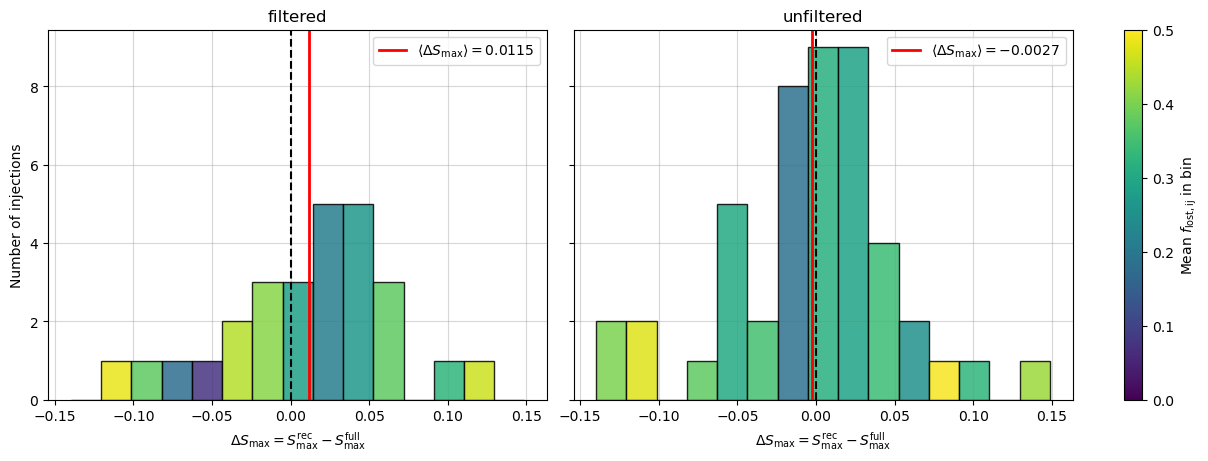

In [3]:
# ==================================================
# Histogram of Delta Smax
# Colour = mean f_lost in each histogram bin
# ==================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

# Same bins for both branches
all_values = quantity_test_results[
    "Smax error"
].to_numpy()

bin_edges = np.histogram_bin_edges(
    all_values,
    bins=15,
)

cmap = plt.cm.viridis

norm = plt.Normalize(
    vmin=0.0,
    vmax=0.5,
)


for axis, branch in zip(
    axes,
    ("filtered", "unfiltered"),
):

    rows = quantity_test_results[
        quantity_test_results["branch"] == branch
    ]

    values = rows[
        "Smax error"
    ].to_numpy()

    f_lost = rows[
        "f_lost_ij"
    ].to_numpy()

    mean_value = np.mean(
        values
    )


    # ==================================================
    # Histogram counts
    # ==================================================

    counts, _ = np.histogram(
        values,
        bins=bin_edges,
    )


    # ==================================================
    # Mean f_lost in each Delta Smax bin
    # ==================================================

    bin_index = np.digitize(
        values,
        bin_edges,
    ) - 1

    # Include values exactly on the upper edge
    bin_index = np.clip(
        bin_index,
        0,
        len(bin_edges) - 2,
    )

    mean_f_lost = np.full(
        len(bin_edges) - 1,
        np.nan,
    )

    for i in range(
        len(mean_f_lost)
    ):

        in_bin = (
            bin_index == i
        )

        if np.any(in_bin):
            mean_f_lost[i] = np.mean(
                f_lost[in_bin]
            )


    # ==================================================
    # Draw coloured histogram bars
    # ==================================================

    widths = np.diff(
        bin_edges
    )

    centres = (
        bin_edges[:-1]
        + 0.5 * widths
    )

    colours = [
        cmap(norm(value))
        if np.isfinite(value)
        else (0.8, 0.8, 0.8, 1.0)
        for value in mean_f_lost
    ]

    axis.bar(
        centres,
        counts,
        width=widths,
        color=colours,
        edgecolor="black",
        align="center",
        alpha=0.85,
    )


    # ==================================================
    # Reference lines
    # ==================================================

    axis.axvline(
        0.0,
        color="black",
        linestyle="--",
    )

    axis.axvline(
        mean_value,
        color="red",
        linestyle="-",
        linewidth=2,
        label=(
            rf"$\langle\Delta S_{{\max}}\rangle"
            rf"={mean_value:.4f}$"
        ),
    )


    axis.set_title(
        branch
    )

    axis.set_xlabel(
        r"$\Delta S_{\max}"
        r"=S_{\max}^{\rm rec}-S_{\max}^{\rm full}$"
    )

    axis.legend()

    axis.set_axisbelow(
        True
    )

    axis.grid(
        alpha=0.5
    )


axes[0].set_ylabel(
    "Number of injections"
)


# ==================================================
# Shared f_lost colour scale
# ==================================================

sm = plt.cm.ScalarMappable(
    norm=norm,
    cmap=cmap,
)

sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    label=r"Mean $f_{\rm lost,ij}$ in bin",
)

plt.show()

## Check the strength of the selected regularisation

The Tikhonov inverse uses the denominator

$$
|\mu_q|^2+\lambda_q^2.
$$

This cell checks how important the regularisation term
$\lambda_q^2$ is compared with the original coupling term
$|\mu_q|^2$.

For every Fourier mode, we calculate

$$
R_q
=
\frac{\lambda_q^2}{|\mu_q|^2},
$$

or equivalently

$$
\log_{10}R_q
=
\log_{10}
\left(
\frac{\lambda_q^2}{|\mu_q|^2}
\right).
$$

The interpretation is therefore

$$
R_q<1
\quad\Rightarrow\quad
\lambda_q^2<|\mu_q|^2,
$$

so the inverse is still mainly controlled by the original coupling term,

$$
R_q=1
\quad\Rightarrow\quad
\lambda_q^2=|\mu_q|^2,
$$

and

$$
R_q>1
\quad\Rightarrow\quad
\lambda_q^2>|\mu_q|^2,
$$

so the regularisation term dominates that Fourier mode.

The heatmaps group these ratios by

$$
a\in\{ij,ii,jj\},
$$

$f_{\rm lost}$ bin, and filtered/unfiltered search branch.

The **top row** shows the median value of

$$
\log_{10}
\left(
\frac{\lambda_q^2}{|\mu_q|^2}
\right),
$$

which describes the typical regularisation strength in each group.

The **bottom row** shows the maximum value, which checks whether any modes
are being regularised extremely strongly.

Each heatmap cell also gives the percentage of modes satisfying

$$
\lambda_q^2>|\mu_q|^2,
$$

i.e. the percentage of modes for which the regularisation term is larger than
the original coupling term.

Therefore, this diagnostic checks whether the selected $A$ produces a
reasonable level of regularisation across different mask losses, or whether
some $f_{\rm lost}$ bins and Fourier modes are being dominated by the
regularisation.

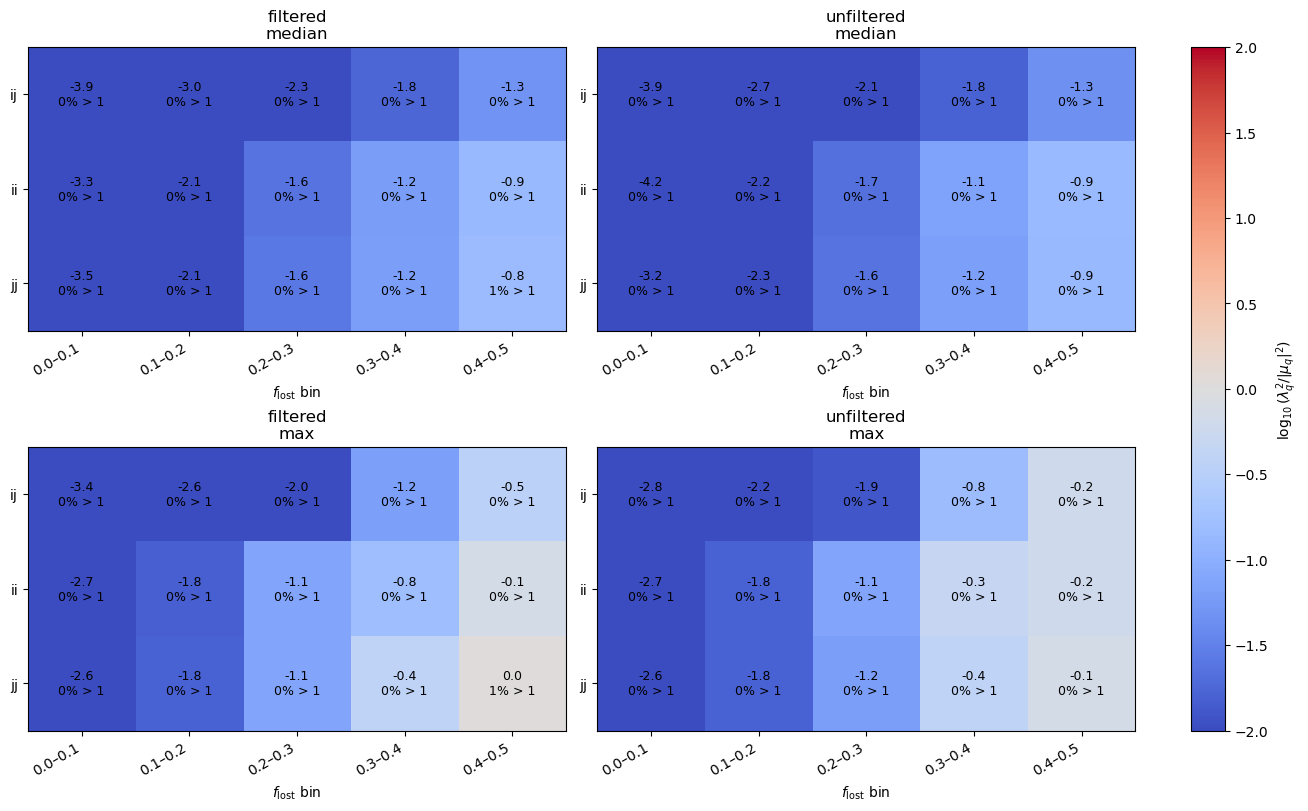

In [4]:
import matplotlib.pyplot as plt
import matplotlib.colors as colours
import numpy as np

# ==================================================
# Heatmaps of lambda_q^2 / |mu_q|^2 by f_lost bin
# top row: median
# bottom row: max
# ==================================================

quantities = (
    "ij",
    "ii",
    "jj",
)

bin_labels = [
    f_lost_bin_label(f_bin)
    for f_bin in range(5)
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 8.0),
    constrained_layout=True,
)

# 0 means lambda_q^2 = |mu_q|^2.
normalisation = colours.TwoSlopeNorm(
    vmin=-2.0,
    vcenter=0.0,
    vmax=2.0,
)

for column, branch in enumerate(
    ("filtered", "unfiltered")
):

    median_matrix = np.full(
        (3, 5),
        np.nan,
    )

    max_matrix = np.full(
        (3, 5),
        np.nan,
    )

    percentage_matrix = np.full(
        (3, 5),
        np.nan,
    )

    for quantity_index, quantity in enumerate(
        quantities
    ):
        for f_bin in range(5):

            log_ratios = []
            stronger = []

            for case in cases:

                if case["branch"] != branch:
                    continue

                if (
                    case[f"f_lost_bin_{quantity}"]
                    != f_bin
                ):
                    continue

                geometry = geometry_by_injection[
                    case["injection_id"]
                ]

                mu = geometry[
                    f"mu_{quantity}"
                ]

                f_lost = case[
                    f"f_lost_{quantity}"
                ]

                maximum_mu = float(
                    np.max(
                        np.abs(mu)
                    )
                )

                mu_squared = (
                    np.abs(mu) ** 2
                )

                w_q = (
                    1.0
                    - mu_squared
                    / maximum_mu**2
                )

                lambda_squared = (
                    SELECTED_A
                    * maximum_mu**2
                    * f_lost
                    / (1.0 - f_lost)
                    * w_q
                )

                valid = (
                    (mu_squared > 0.0)
                    & (lambda_squared > 0.0)
                )

                current_log_ratios = np.log10(
                    lambda_squared[valid]
                    / mu_squared[valid]
                )

                log_ratios.extend(
                    current_log_ratios
                )

                stronger.extend(
                    (
                        lambda_squared[valid]
                        > mu_squared[valid]
                    )
                )

            if not log_ratios:
                continue

            log_ratios = np.asarray(
                log_ratios
            )

            stronger = np.asarray(
                stronger
            )

            median_matrix[
                quantity_index,
                f_bin,
            ] = np.median(
                log_ratios
            )

            max_matrix[
                quantity_index,
                f_bin,
            ] = np.max(
                log_ratios
            )

            percentage_matrix[
                quantity_index,
                f_bin,
            ] = (
                100.0
                * np.mean(
                    stronger
                )
            )

    # ----------------------------------------------
    # Top row: median
    # ----------------------------------------------
    axis = axes[0, column]

    image = axis.imshow(
        median_matrix,
        cmap="coolwarm",
        norm=normalisation,
        aspect="auto",
    )

    axis.set_xticks(
        range(5),
        labels=bin_labels,
        rotation=30,
        ha="right",
    )

    axis.set_yticks(
        range(3),
        labels=quantities,
    )

    axis.set_xlabel(
        r"$f_{\rm lost}$ bin"
    )

    axis.set_title(
        f"{branch}\nmedian"
    )

    for quantity_index in range(3):
        for f_bin in range(5):

            median_value = median_matrix[
                quantity_index,
                f_bin,
            ]

            percentage = percentage_matrix[
                quantity_index,
                f_bin,
            ]

            if not np.isfinite(median_value):
                continue

            axis.text(
                f_bin,
                quantity_index,
                (
                    f"{median_value:.1f}\n"
                    f"{percentage:.0f}% > 1"
                ),
                ha="center",
                va="center",
                fontsize=9,
            )

    # ----------------------------------------------
    # Bottom row: max
    # ----------------------------------------------
    axis = axes[1, column]

    image = axis.imshow(
        max_matrix,
        cmap="coolwarm",
        norm=normalisation,
        aspect="auto",
    )

    axis.set_xticks(
        range(5),
        labels=bin_labels,
        rotation=30,
        ha="right",
    )

    axis.set_yticks(
        range(3),
        labels=quantities,
    )

    axis.set_xlabel(
        r"$f_{\rm lost}$ bin"
    )

    axis.set_title(
        f"{branch}\nmax"
    )

    for quantity_index in range(3):
        for f_bin in range(5):

            max_value = max_matrix[
                quantity_index,
                f_bin,
            ]

            percentage = percentage_matrix[
                quantity_index,
                f_bin,
            ]

            if not np.isfinite(max_value):
                continue

            axis.text(
                f_bin,
                quantity_index,
                (
                    f"{max_value:.1f}\n"
                    f"{percentage:.0f}% > 1"
                ),
                ha="center",
                va="center",
                fontsize=9,
            )

colourbar = fig.colorbar(
    image,
    ax=axes,
)

colourbar.set_label(
    r"$\log_{10}(\lambda_q^2/|\mu_q|^2)$"
)

plt.show()

NO-REGULARISATION held-out individual results:


,injection_id,branch,alpha_deg,f_lost_ij,f_lost_ii,f_lost_jj,Full Smax,Recovered Smax,Smax error,Absolute Smax error,Full beta bin,Recovered beta bin,Beta error in bins,S(beta) RMSE,injected_file
0,0,filtered,25.0,0.025391,0.015625,0.007812,0.446103,0.460153,0.014050,0.014050,126,126,0,0.012218,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
1,2,filtered,25.0,0.126953,0.062500,0.054688,0.479178,0.496482,0.017305,0.017305,126,126,0,0.042181,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
2,3,filtered,25.0,0.173828,0.125000,0.046875,0.504091,0.544740,0.040649,0.040649,126,126,0,0.043738,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
3,5,filtered,25.0,0.273438,0.179688,0.093750,0.410559,0.404550,-0.006009,0.006009,126,126,0,0.060941,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
4,6,filtered,25.0,0.324219,0.156250,0.179688,0.436044,0.542066,0.106022,0.106022,126,126,0,0.063346,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,140,unfiltered,89.0,0.472656,0.406250,0.429688,0.833361,0.841641,0.008280,0.008280,126,126,0,0.100605,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
70,142,unfiltered,90.0,0.412109,0.406250,0.406250,0.991331,1.008574,0.017243,0.017243,126,126,0,0.159523,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
71,143,unfiltered,88.0,0.488281,0.398438,0.390625,0.882556,0.936851,0.054295,0.054295,126,126,0,0.042268,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...
72,144,unfiltered,90.0,0.414062,0.382812,0.382812,0.998919,1.001269,0.002350,0.002350,126,126,0,0.077378,/hydrarepo/xluo/circles-in-the-sky/perfect_inj...



NO-REGULARISATION held-out summary:


,branch,test_maps,mean_full_Smax,mean_recovered_Smax,mean_signed_Smax_error,mean_absolute_Smax_error,maximum_absolute_Smax_error,mean_beta_error_bins,maximum_beta_error_bins,mean_Sbeta_RMSE
0,filtered,27,0.343820,0.359941,0.016121,0.045012,0.124278,1.925926,16,0.058257
1,unfiltered,47,0.880114,0.889844,0.009729,0.041908,0.179667,0.000000,0,0.065009



Number of invalid unregularised cases: 0


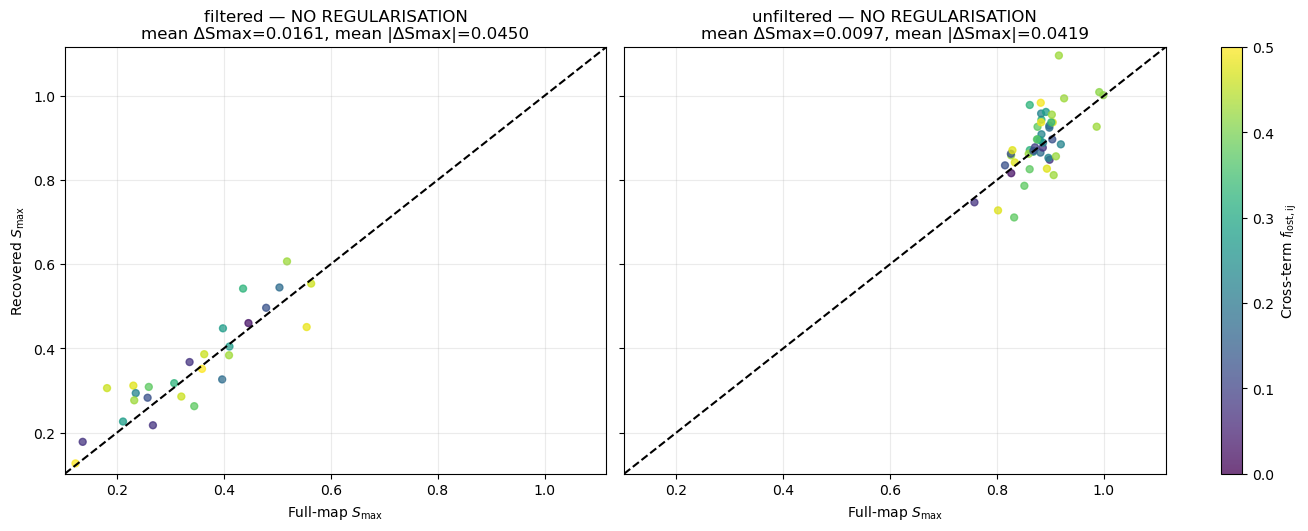

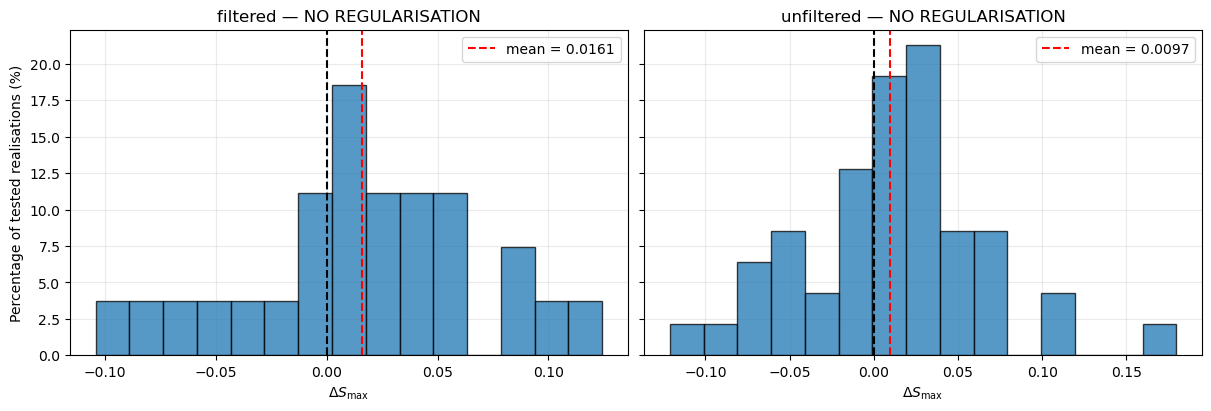


FILTERED: alpha < 45 deg — NO REGULARISATION

Worst Smax errors:


,injection_id,branch,alpha_deg,f_lost_ij,Full Smax,Recovered Smax,Smax error,Beta error in bins
61,123,filtered,36.0,0.458984,0.181535,0.305812,0.124278,16
4,6,filtered,25.0,0.324219,0.436044,0.542066,0.106022,0
62,127,filtered,26.0,0.482422,0.554982,0.450761,-0.104221,0
5,8,filtered,25.0,0.425781,0.518234,0.606616,0.088382,0
9,17,filtered,30.0,0.375000,0.344687,0.262905,-0.081782,0
13,29,filtered,35.0,0.474609,0.230769,0.311764,0.080996,0
7,13,filtered,30.0,0.175781,0.396914,0.326476,-0.070438,0
15,34,filtered,40.0,0.224609,0.235279,0.293915,0.058637,0
14,31,filtered,40.0,0.074219,0.267388,0.217626,-0.049762,0
8,15,filtered,30.0,0.275391,0.398399,0.447769,0.049370,0



Worst beta errors:


,injection_id,branch,alpha_deg,f_lost_ij,Full Smax,Recovered Smax,Smax error,Beta error in bins
61,123,filtered,36.0,0.458984,0.181535,0.305812,0.124278,16
12,25,filtered,35.0,0.275391,0.211464,0.226474,0.015010,15
10,21,filtered,35.0,0.074219,0.136003,0.178234,0.042231,10
17,37,filtered,40.0,0.375000,0.259665,0.308613,0.048949,7
65,135,filtered,27.0,0.496094,0.122546,0.127057,0.004511,4
5,8,filtered,25.0,0.425781,0.518234,0.606616,0.088382,0
4,6,filtered,25.0,0.324219,0.436044,0.542066,0.106022,0
2,3,filtered,25.0,0.173828,0.504091,0.544740,0.040649,0
3,5,filtered,25.0,0.273438,0.410559,0.404550,-0.006009,0
1,2,filtered,25.0,0.126953,0.479178,0.496482,0.017305,0



UNFILTERED: alpha >= 45 deg — NO REGULARISATION

Worst Smax errors:


,injection_id,branch,alpha_deg,f_lost_ij,Full Smax,Recovered Smax,Smax error,Beta error in bins
55,112,unfiltered,80.0,0.425781,0.915820,1.095487,0.179667,0
31,67,unfiltered,55.0,0.375000,0.832108,0.710952,-0.121156,0
53,110,unfiltered,80.0,0.324219,0.861328,0.978007,0.116679,0
68,139,unfiltered,88.0,0.492188,0.881895,0.983285,0.101390,0
40,87,unfiltered,65.0,0.425781,0.906059,0.811495,-0.094563,0
29,64,unfiltered,55.0,0.224609,0.882585,0.957680,0.075095,0
22,49,unfiltered,45.0,0.474609,0.802006,0.727754,-0.074252,0
30,65,unfiltered,55.0,0.275391,0.891606,0.961451,0.069845,0
35,78,unfiltered,60.0,0.425781,0.925582,0.993694,0.068112,0
36,79,unfiltered,60.0,0.474609,0.893407,0.826727,-0.066680,0



Worst beta errors:


,injection_id,branch,alpha_deg,f_lost_ij,Full Smax,Recovered Smax,Smax error,Beta error in bins
19,41,unfiltered,45.0,0.074219,0.898434,0.847932,-0.050502,0
20,42,unfiltered,45.0,0.125000,0.815023,0.834657,0.019634,0
21,43,unfiltered,45.0,0.173828,0.881411,0.864886,-0.016525,0
22,49,unfiltered,45.0,0.474609,0.802006,0.727754,-0.074252,0
23,53,unfiltered,50.0,0.175781,0.897915,0.928764,0.030849,0
24,54,unfiltered,50.0,0.224609,0.883236,0.908493,0.025257,0
25,56,unfiltered,50.0,0.324219,0.883149,0.943044,0.059895,0
26,60,unfiltered,55.0,0.025391,0.826682,0.816001,-0.010682,0
27,61,unfiltered,55.0,0.076172,0.885769,0.876752,-0.009017,0
28,63,unfiltered,55.0,0.175781,0.898016,0.924116,0.026101,0


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==================================================
# NO-REGULARISATION baseline
#
# Same held-out test cases as the regularised analysis.
#
# alpha < 45 deg  -> filtered
# alpha >= 45 deg -> unfiltered
#
# NO:
#   f_reg
#   lambda_1
#   lambda_2
#   epsilon penalty
#   f_lost penalty
#   null calibration
#   upper-level optimisation
#   coordinate search
# ==================================================


# ==================================================
# Exact unregularised inverse
# ==================================================

def inverse_no_regularisation(
    C_hat,
    mu,
):
    C_hat = np.asarray(C_hat)
    mu = np.asarray(mu)

    # No thresholding or pseudoinverse cutoff is used.
    # If mu is exactly zero, the inverse genuinely does
    # not exist at that mode.
    if np.any(np.abs(mu) == 0.0):
        return None

    inverse_filter = (
        np.conj(mu)
        / np.abs(mu) ** 2
    )

    return np.fft.ifft(
        np.fft.fft(C_hat)
        * inverse_filter
    )


# ==================================================
# Recover S(beta) with NO regularisation
# ==================================================

def recover_case_no_regularisation(
    case,
):
    geometry = geometry_by_injection[
        case["injection_id"]
    ]

    recovered_ij = inverse_no_regularisation(
        case["C_hat_ij"],
        geometry["mu_ij"],
    )

    recovered_ii = inverse_no_regularisation(
        case["C_hat_ii"],
        geometry["mu_ii"],
    )

    recovered_jj = inverse_no_regularisation(
        case["C_hat_jj"],
        geometry["mu_jj"],
    )

    if (
        recovered_ij is None
        or recovered_ii is None
        or recovered_jj is None
    ):
        return None

    recovered_S = calculate_S(
        recovered_ij,
        recovered_ii,
        recovered_jj,
    )

    if recovered_S is None:
        return None

    recovered_S[
        ~geometry["eligible_beta"]
    ] = np.nan

    return recovered_S


# ==================================================
# Apply to the SAME held-out test cases
# ==================================================

no_reg_result_rows = []
invalid_cases = []

for case in test_cases:

    branch = case["branch"]

    # Extra safety: enforce the actual search rule.
    if (
        branch == "filtered"
        and case["alpha_deg"] >= 45.0
    ):
        continue

    if (
        branch == "unfiltered"
        and case["alpha_deg"] < 45.0
    ):
        continue

    recovered_S = (
        recover_case_no_regularisation(
            case
        )
    )

    if recovered_S is None:
        invalid_cases.append(
            {
                "injection_id": case[
                    "injection_id"
                ],
                "branch": branch,
                "alpha_deg": case[
                    "alpha_deg"
                ],
                "reason": (
                    "singular or invalid "
                    "unregularised inverse"
                ),
            }
        )
        continue

    full_S = case["full_S"]

    valid = (
        np.isfinite(recovered_S)
        & np.isfinite(full_S)
    )

    if not np.any(valid):
        invalid_cases.append(
            {
                "injection_id": case[
                    "injection_id"
                ],
                "branch": branch,
                "alpha_deg": case[
                    "alpha_deg"
                ],
                "reason": (
                    "no finite S(beta)"
                ),
            }
        )
        continue

    full_for_max = np.where(
        valid,
        full_S,
        -np.inf,
    )

    recovered_for_max = np.where(
        valid,
        recovered_S,
        -np.inf,
    )

    full_beta = int(
        np.argmax(
            full_for_max
        )
    )

    recovered_beta = int(
        np.argmax(
            recovered_for_max
        )
    )

    full_smax = float(
        full_for_max[
            full_beta
        ]
    )

    recovered_smax = float(
        recovered_for_max[
            recovered_beta
        ]
    )

    beta_difference = abs(
        recovered_beta
        - full_beta
    )

    beta_error = min(
        beta_difference,
        NPHI - beta_difference,
    )

    no_reg_result_rows.append(
        {
            "injection_id": case[
                "injection_id"
            ],
            "branch": branch,
            "alpha_deg": case[
                "alpha_deg"
            ],

            "f_lost_ij": case[
                "f_lost_ij"
            ],
            "f_lost_ii": case[
                "f_lost_ii"
            ],
            "f_lost_jj": case[
                "f_lost_jj"
            ],

            "Full Smax": full_smax,

            "Recovered Smax": (
                recovered_smax
            ),

            "Smax error": (
                recovered_smax
                - full_smax
            ),

            "Absolute Smax error": abs(
                recovered_smax
                - full_smax
            ),

            "Full beta bin": (
                full_beta
            ),

            "Recovered beta bin": (
                recovered_beta
            ),

            "Beta error in bins": (
                beta_error
            ),

            "S(beta) RMSE": float(
                np.sqrt(
                    np.mean(
                        (
                            recovered_S[
                                valid
                            ]
                            - full_S[
                                valid
                            ]
                        ) ** 2
                    )
                )
            ),

            "injected_file": case[
                "injected_file"
            ],
        }
    )


# ==================================================
# Results table
# ==================================================

no_reg_test_results = pd.DataFrame(
    no_reg_result_rows
)

invalid_no_reg_results = pd.DataFrame(
    invalid_cases
)


# ==================================================
# Held-out summary
# ==================================================

no_reg_test_summary = (
    no_reg_test_results
    .groupby(
        "branch",
        observed=True,
    )
    .agg(
        test_maps=(
            "injection_id",
            "nunique",
        ),

        mean_full_Smax=(
            "Full Smax",
            "mean",
        ),

        mean_recovered_Smax=(
            "Recovered Smax",
            "mean",
        ),

        mean_signed_Smax_error=(
            "Smax error",
            "mean",
        ),

        mean_absolute_Smax_error=(
            "Absolute Smax error",
            "mean",
        ),

        maximum_absolute_Smax_error=(
            "Absolute Smax error",
            "max",
        ),

        mean_beta_error_bins=(
            "Beta error in bins",
            "mean",
        ),

        maximum_beta_error_bins=(
            "Beta error in bins",
            "max",
        ),

        mean_Sbeta_RMSE=(
            "S(beta) RMSE",
            "mean",
        ),
    )
    .reset_index()
)


print(
    "NO-REGULARISATION "
    "held-out individual results:"
)

display(
    no_reg_test_results
)


print(
    "\nNO-REGULARISATION "
    "held-out summary:"
)

display(
    no_reg_test_summary
)


print(
    "\nNumber of invalid "
    "unregularised cases:",
    len(invalid_no_reg_results),
)

if len(
    invalid_no_reg_results
) > 0:

    display(
        invalid_no_reg_results
    )


# ==================================================
# Full Smax versus recovered Smax
# ==================================================

lower = min(
    no_reg_test_results[
        "Full Smax"
    ].min(),
    no_reg_test_results[
        "Recovered Smax"
    ].min(),
) - 0.02

upper = max(
    no_reg_test_results[
        "Full Smax"
    ].max(),
    no_reg_test_results[
        "Recovered Smax"
    ].max(),
) + 0.02


fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.2),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)


for axis, branch in zip(
    axes,
    (
        "filtered",
        "unfiltered",
    ),
):

    rows = no_reg_test_results[
        no_reg_test_results[
            "branch"
        ] == branch
    ]

    points = axis.scatter(
        rows["Full Smax"],
        rows["Recovered Smax"],
        c=rows["f_lost_ij"],
        vmin=0.0,
        vmax=0.5,
        cmap="viridis",
        s=25,
        alpha=0.75,
    )

    axis.plot(
        [lower, upper],
        [lower, upper],
        "k--",
    )

    axis.set(
        xlim=(lower, upper),
        ylim=(lower, upper),
        xlabel=(
            r"Full-map $S_{\max}$"
        ),
    )

    axis.set_title(
        f"{branch} — NO REGULARISATION\n"
        f"mean ΔSmax="
        f"{rows['Smax error'].mean():.4f}, "
        f"mean |ΔSmax|="
        f"{rows['Absolute Smax error'].mean():.4f}"
    )

    axis.grid(
        alpha=0.25
    )


axes[0].set_ylabel(
    r"Recovered $S_{\max}$"
)

fig.colorbar(
    points,
    ax=axes,
    label=(
        r"Cross-term $f_{\rm lost,ij}$"
    ),
)

plt.show()


# ==================================================
# Smax-error histograms
# ==================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
    sharey=True,
    constrained_layout=True,
)


for axis, branch in zip(
    axes,
    (
        "filtered",
        "unfiltered",
    ),
):

    values = (
        no_reg_test_results.loc[
            no_reg_test_results[
                "branch"
            ] == branch,
            "Smax error",
        ]
        .to_numpy()
    )

    weights = (
        np.ones(
            len(values)
        )
        * 100.0
        / len(values)
    )

    mean_value = np.mean(
        values
    )

    axis.hist(
        values,
        bins=15,
        weights=weights,
        edgecolor="black",
        alpha=0.75,
    )

    axis.axvline(
        0.0,
        color="black",
        linestyle="--",
    )

    axis.axvline(
        mean_value,
        color="red",
        linestyle="--",
        label=(
            f"mean = "
            f"{mean_value:.4f}"
        ),
    )

    axis.set_title(
        f"{branch} — "
        "NO REGULARISATION"
    )

    axis.set_xlabel(
        r"$\Delta S_{\max}$"
    )

    axis.legend()
    axis.set_axisbelow(True)
    axis.grid(True, alpha=0.25)

axes[0].set_ylabel(
    "Percentage of tested "
    "realisations (%)"
)

plt.show()


# ==================================================
# Worst cases in actual search branches
# ==================================================

filtered_small = (
    no_reg_test_results[
        (
            no_reg_test_results[
                "alpha_deg"
            ] < 45.0
        )
        & (
            no_reg_test_results[
                "branch"
            ] == "filtered"
        )
    ]
    .copy()
)

unfiltered_large = (
    no_reg_test_results[
        (
            no_reg_test_results[
                "alpha_deg"
            ] >= 45.0
        )
        & (
            no_reg_test_results[
                "branch"
            ] == "unfiltered"
        )
    ]
    .copy()
)


columns = [
    "injection_id",
    "branch",
    "alpha_deg",
    "f_lost_ij",
    "Full Smax",
    "Recovered Smax",
    "Smax error",
    "Beta error in bins",
]


print(
    "\n========================================"
)
print(
    "FILTERED: alpha < 45 deg "
    "— NO REGULARISATION"
)
print(
    "========================================"
)

print(
    "\nWorst Smax errors:"
)

display(
    filtered_small
    .sort_values(
        "Absolute Smax error",
        ascending=False,
    )[columns]
    .head(15)
)


print(
    "\nWorst beta errors:"
)

display(
    filtered_small
    .sort_values(
        "Beta error in bins",
        ascending=False,
    )[columns]
    .head(15)
)


print(
    "\n========================================"
)
print(
    "UNFILTERED: alpha >= 45 deg "
    "— NO REGULARISATION"
)
print(
    "========================================"
)

print(
    "\nWorst Smax errors:"
)

display(
    unfiltered_large
    .sort_values(
        "Absolute Smax error",
        ascending=False,
    )[columns]
    .head(15)
)


print(
    "\nWorst beta errors:"
)

display(
    unfiltered_large
    .sort_values(
        "Beta error in bins",
        ascending=False,
    )[columns]
    .head(15)
)

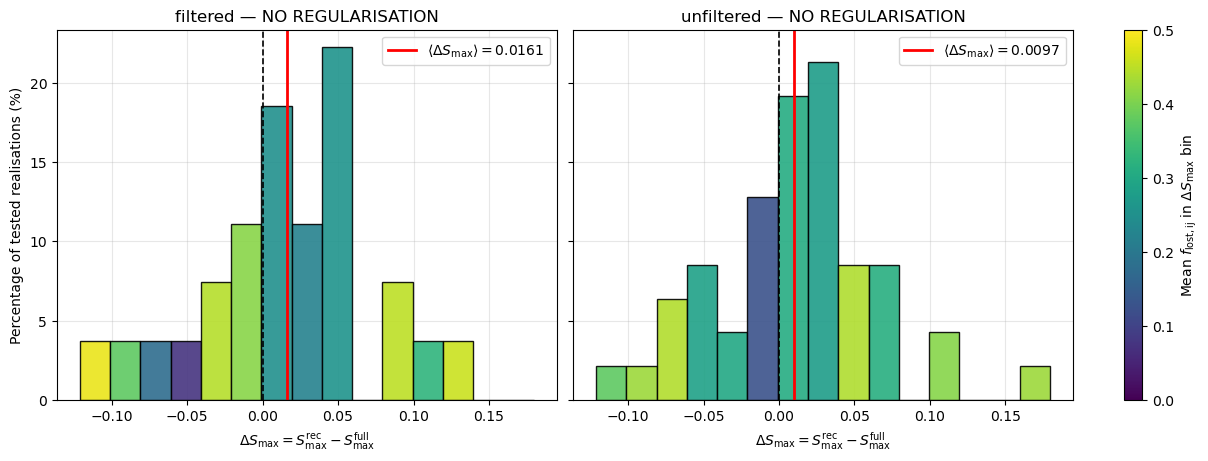

In [6]:
# ==================================================
# Smax-error histograms
# Bar height = percentage of tested realisations
# Bar colour = mean f_lost_ij in each Delta Smax bin
# ==================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)


# ==================================================
# Common histogram bins
# ==================================================

all_values = no_reg_test_results[
    "Smax error"
].to_numpy()

bin_edges = np.histogram_bin_edges(
    all_values,
    bins=15,
)

bin_widths = np.diff(
    bin_edges
)

bin_centres = (
    bin_edges[:-1]
    + 0.5 * bin_widths
)


# ==================================================
# f_lost colour scale
# ==================================================

cmap = plt.cm.viridis

norm = plt.Normalize(
    vmin=0.0,
    vmax=0.5,
)


# ==================================================
# Plot each branch
# ==================================================

for axis, branch in zip(
    axes,
    ("filtered", "unfiltered"),
):

    rows = no_reg_test_results[
        no_reg_test_results["branch"] == branch
    ]

    values = rows[
        "Smax error"
    ].to_numpy()

    f_lost = rows[
        "f_lost_ij"
    ].to_numpy()

    mean_value = np.mean(
        values
    )

    # Percentage weights
    weights = (
        np.ones(len(values))
        * 100.0
        / len(values)
    )

    # Histogram heights in percentage
    percentages, _ = np.histogram(
        values,
        bins=bin_edges,
        weights=weights,
    )

    # Find which points fall into which bin
    bin_indices = np.digitize(
        values,
        bin_edges,
    ) - 1

    bin_indices = np.clip(
        bin_indices,
        0,
        len(bin_edges) - 2,
    )

    # Mean f_lost in each bin
    mean_f_lost = np.full(
        len(bin_edges) - 1,
        np.nan,
    )

    for bin_index in range(
        len(mean_f_lost)
    ):
        in_bin = (
            bin_indices == bin_index
        )

        if np.any(in_bin):
            mean_f_lost[bin_index] = np.mean(
                f_lost[in_bin]
            )

    # Colours for bars
    colours = [
        cmap(norm(value))
        if np.isfinite(value)
        else (0.85, 0.85, 0.85, 1.0)
        for value in mean_f_lost
    ]

    # Draw histogram bars
    axis.bar(
        bin_centres,
        percentages,
        width=bin_widths,
        color=colours,
        edgecolor="black",
        align="center",
        alpha=0.9,
    )

    # Reference lines
    axis.axvline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=1.2,
    )

    axis.axvline(
        mean_value,
        color="red",
        linestyle="-",
        linewidth=2,
        label=(
            rf"$\langle \Delta S_{{\max}} \rangle"
            rf"={mean_value:.4f}$"
        ),
    )

    axis.set_title(
        f"{branch} — NO REGULARISATION"
    )

    axis.set_xlabel(
        r"$\Delta S_{\max}"
        r"=S_{\max}^{\rm rec}-S_{\max}^{\rm full}$"
    )

    axis.legend()
    axis.set_axisbelow(True)
    axis.grid(True, alpha=0.3)


axes[0].set_ylabel(
    "Percentage of tested realisations (%)"
)


# ==================================================
# Shared colour bar
# ==================================================

sm = plt.cm.ScalarMappable(
    norm=norm,
    cmap=cmap,
)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes,
)

cbar.set_label(
    r"Mean $f_{\rm lost,ij}$ in $\Delta S_{\max}$ bin"
)

plt.show()